# BrainScan – Classification d'IRM cérébrales par CNN
**Objectif :** classer des IRM cérébrales en 4 classes (`glioma`, `meningioma`, `notumor`, `pituitary`) avec un CNN (TensorFlow/Keras + OpenCV).
**Outil d'aide au diagnostic, pas un diagnostic.**

**Organisation :** sections 0 → 1 en local (prétraitement) · sections 2 → 3 sur Colab (GPU) · section 4 en local (déploiement).

## 0. Imports et configuration

In [1]:
import os
import time
import json
import random

import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils import shuffle, class_weight
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from tensorflow.keras import layers, models, callbacks, optimizers
from tensorflow.keras.utils import to_categorical, plot_model

# ---- Configuration ----
BASE_DIR      = r"C:\BrainScan"
DATA_DIR      = os.path.join(BASE_DIR, "data")
PROCESSED_DIR = os.path.join(BASE_DIR, "processed")  
MODEL_DIR     = os.path.join(BASE_DIR, "models")
IMG_SIZE      = 224
VALID_EXT     = (".jpeg", ".jpg", ".bmp", ".png")
SEED          = 42
TEST_SIZE     = 0.2

os.makedirs(PROCESSED_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)

random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

print("NumPy       :", np.__version__)
print("OpenCV      :", cv2.__version__)
print("TensorFlow  :", tf.__version__)
print("GPU détecté :", tf.config.list_physical_devices("GPU"))

NumPy       : 2.5.3
OpenCV      : 5.0.0
TensorFlow  : 2.21.0
GPU détecté : []


## 1. Chargement et prétraitement du dataset

### 1.1 Exploration des classes

In [3]:
# Les noms des dossiers
classes = sorted(d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d)))
print("Classes :", classes)

for c in classes:
    print(f"{c} {len(os.listdir(os.path.join(DATA_DIR, c)))} fichiers")

Classes : ['glioma', 'meningioma', 'notumor', 'pituitary']
glioma 1621 fichiers
meningioma 1645 fichiers
notumor 2000 fichiers
pituitary 1757 fichiers


### 1.2 Contrôle qualité
On **ne supprime pas** les fichiers invalides du disque : le code les **ignore** et les compte 


In [5]:
audit = {}
for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    n_valides = n_mauvaise_ext = n_illisibles = 0

    for file in os.listdir(class_path):
        if not file.lower().endswith(VALID_EXT):
            n_mauvaise_ext += 1
            continue
        try:
            img = cv2.imread(os.path.join(class_path, file))
            if img is None:                
                n_illisibles += 1
            else:
                n_valides += 1
        except Exception as e:
            print("Erreur :", file, e)
            n_illisibles += 1

    audit[class_name] = (n_valides, n_mauvaise_ext, n_illisibles)
    print(f"{class_name} valides={n_valides}  mauvaise_ext={n_mauvaise_ext}  illisibles={n_illisibles}")

glioma valides=1621  mauvaise_ext=0  illisibles=0
meningioma valides=1645  mauvaise_ext=0  illisibles=0
notumor valides=2000  mauvaise_ext=0  illisibles=0
pituitary valides=1757  mauvaise_ext=0  illisibles=0


### 1.3 Chargement + redimensionnement

In [6]:
images, labels, ignores = [], [], []

start = time.time()
for class_name in classes:
    class_path = os.path.join(DATA_DIR, class_name)
    for file in os.listdir(class_path):
        if not file.lower().endswith(VALID_EXT):
            ignores.append(file); continue
        try:
            img = cv2.imread(os.path.join(class_path, file), cv2.IMREAD_GRAYSCALE)
            if img is None:
                ignores.append(file); continue
            img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
            images.append(img)
            labels.append(class_name)      # même indice dans les deux listes
        except Exception as e:
            print("Erreur :", file, e)
            ignores.append(file)

print(f"{len(images)} images chargées, {len(ignores)} ignorées en {time.time()-start:.1f}s")

7023 images chargées, 0 ignorées en 8.9s


### 1.4 Conversion en tableaux NumPy et mélange

In [7]:
X = np.array(images, dtype=np.uint8)
y = np.array(labels)
del images, labels                       # libère la mémoire

X, y = shuffle(X, y, random_state=SEED)  # mélange en gardant la correspondance image/label
X = X[..., np.newaxis]                   # (N, 224, 224) -> (N, 224, 224, 1)

print("X :", X.shape, X.dtype)
print("y :", y.shape, y[:5])

X : (7023, 224, 224, 1) uint8
y : (7023,) ['notumor' 'meningioma' 'meningioma' 'notumor' 'pituitary']


### 1.5 Distribution des classes

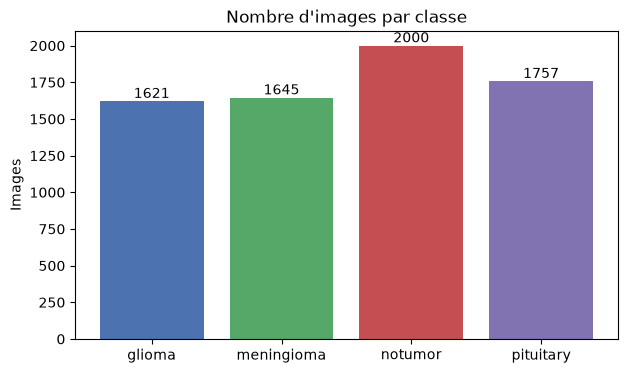

In [8]:
noms, comptes = np.unique(y, return_counts=True)

plt.figure(figsize=(7, 4))
bars = plt.bar(noms, comptes, color=["#4C72B0", "#55A868", "#C44E52", "#8172B2"])
plt.bar_label(bars)
plt.title("Nombre d'images par classe")
plt.ylabel("Images")
plt.show()

### 1.6 Échantillon d'images par classe

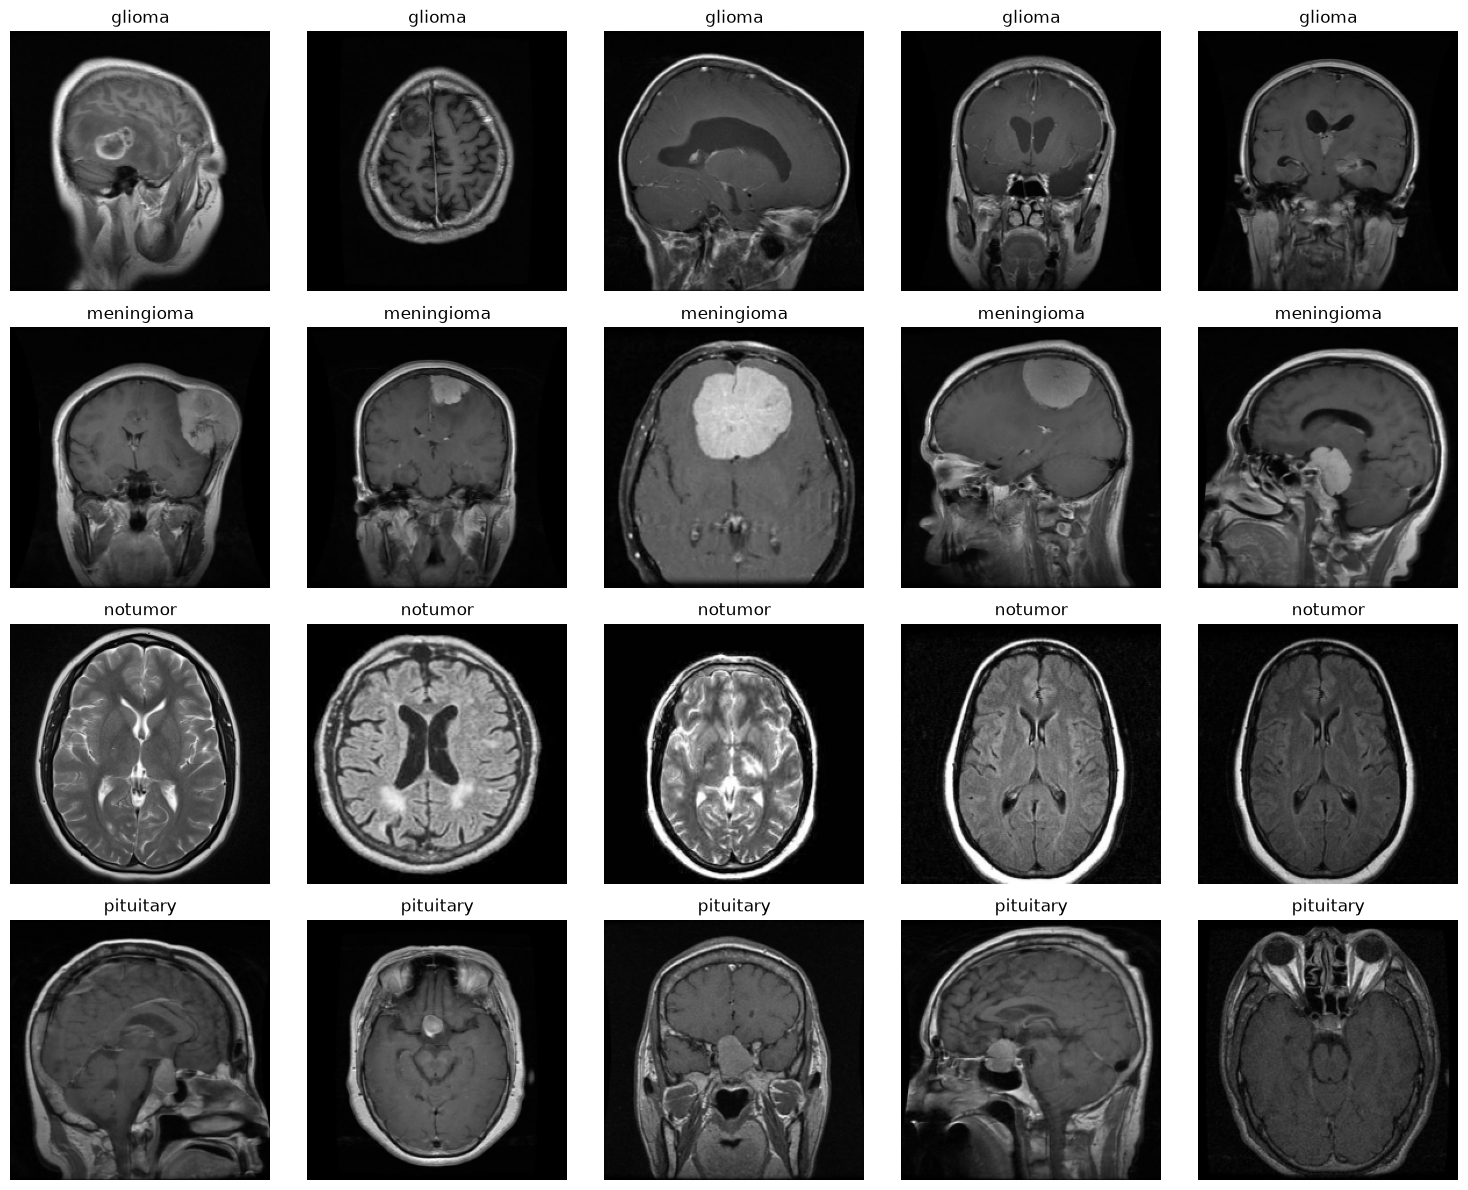

In [9]:
n_ex = 5
fig, axes = plt.subplots(len(classes), n_ex, figsize=(3 * n_ex, 3 * len(classes)))
for i, c in enumerate(classes):
    idx = np.where(y == c)[0][:n_ex]
    for j, k in enumerate(idx):
        axes[i, j].imshow(X[k].squeeze(), cmap="gray")
        axes[i, j].set_title(c)
        axes[i, j].axis("off")
plt.tight_layout()
plt.show()

### 1.7 Vérification de l'équilibre des classes

In [11]:
ratio = comptes.max() / comptes.min()
print(dict(zip(noms, comptes)))
print(f"Ratio classe max / classe min : {ratio:.2f}")

DESEQUILIBRE = ratio > 1.5
print("Déséquilibre significatif -> rééquilibrage nécessaire" if DESEQUILIBRE
      else "Classes quasi équilibrées -> pas de rééquilibrage lourd")

{np.str_('glioma'): np.int64(1621), np.str_('meningioma'): np.int64(1645), np.str_('notumor'): np.int64(2000), np.str_('pituitary'): np.int64(1757)}
Ratio classe max / classe min : 1.23
Classes quasi équilibrées -> pas de rééquilibrage lourd


### 1.8 Encodage des labels

In [12]:
le = LabelEncoder()
y_int = le.fit_transform(y)              # 'glioma' -> 0, 'meningioma' -> 1, ...
class_names = list(le.classes_)
NUM_CLASSES = len(class_names)

print("Correspondance :", dict(zip(class_names, range(NUM_CLASSES))))

Correspondance : {np.str_('glioma'): 0, np.str_('meningioma'): 1, np.str_('notumor'): 2, np.str_('pituitary'): 3}


### 1.9 Séparation train / test
Le split est fait **avant** tout rééquilibrage (sinon fuite de données), avec `stratify` pour garder les mêmes proportions de classes. Le rééquilibrage éventuel se fait **uniquement sur le train**, via des poids de classes.

In [13]:
X_train, X_test, y_train_int, y_test_int = train_test_split(
    X, y_int, test_size=TEST_SIZE, stratify=y_int, random_state=SEED
)
del X, y

print("Train :", X_train.shape, " Test :", X_test.shape)
print("Train par classe :", np.bincount(y_train_int))
print("Test  par classe :", np.bincount(y_test_int))

# Poids de classes calculés sur le TRAIN uniquement
poids = class_weight.compute_class_weight("balanced", classes=np.unique(y_train_int), y=y_train_int)
CLASS_WEIGHTS = dict(enumerate(poids))
USE_CLASS_WEIGHTS = DESEQUILIBRE
print("Poids de classes :", {k: round(v, 2) for k, v in CLASS_WEIGHTS.items()}, "| utilisés :", USE_CLASS_WEIGHTS)

Train : (5618, 224, 224, 1)  Test : (1405, 224, 224, 1)
Train par classe : [1297 1316 1600 1405]
Test  par classe : [324 329 400 352]
Poids de classes : {0: np.float64(1.08), 1: np.float64(1.07), 2: np.float64(0.88), 3: np.float64(1.0)} | utilisés : False


### 1.10 Sauvegarde des données pour Colab
Données **non normalisées** (uint8) : fichier léger. Envoie le `.npz` sur ton Google Drive.

In [14]:
NPZ_PATH = os.path.join(PROCESSED_DIR, "brainscan_data.npz")
np.savez_compressed(NPZ_PATH, X_train=X_train, X_test=X_test,
                    y_train_int=y_train_int, y_test_int=y_test_int,
                    class_names=np.array(class_names))
print("Sauvegardé :", NPZ_PATH, f"({os.path.getsize(NPZ_PATH)/1e6:.0f} Mo)")

with open(os.path.join(MODEL_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

Sauvegardé : C:\BrainScan\processed\brainscan_data.npz (208 Mo)


### 1.11 Normalisation des pixels dans [0, 1] et one-hot

In [15]:
X_train = X_train.astype("float32") / 255.0
X_test  = X_test.astype("float32") / 255.0

y_train = to_categorical(y_train_int, NUM_CLASSES)
y_test  = to_categorical(y_test_int, NUM_CLASSES)

print("X_train :", X_train.shape, X_train.dtype, "| min/max :", X_train.min(), X_train.max())
print("y_train :", y_train.shape, "| exemple :", y_train[0], "->", class_names[y_train_int[0]])

X_train : (5618, 224, 224, 1) float32 | min/max : 0.0 1.0
y_train : (5618, 4) | exemple : [0. 1. 0. 0.] -> meningioma


## 2. Conception du modèle CNN

**Sur Colab** : monte ton Drive, mets `NPZ_PATH` vers le fichier envoyé, puis lance la cellule de rechargement. En local, elle ne fait rien si les données sont déjà en mémoire.

In [16]:
# --- Colab uniquement (décommenter) ---
# from google.colab import drive
# drive.mount("/content/drive")
# NPZ_PATH  = "/content/drive/MyDrive/BrainScan/brainscan_data.npz"
# MODEL_DIR = "/content/drive/MyDrive/BrainScan/models"
# import os, time, json, numpy as np, matplotlib.pyplot as plt, tensorflow as tf
# from tensorflow.keras import layers, models, callbacks, optimizers
# from tensorflow.keras.utils import to_categorical, plot_model
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
# from sklearn.utils import class_weight
# os.makedirs(MODEL_DIR, exist_ok=True)

if "X_train" not in globals():
    d = np.load(NPZ_PATH)
    X_train = d["X_train"].astype("float32") / 255.0
    X_test  = d["X_test"].astype("float32") / 255.0
    y_train_int, y_test_int = d["y_train_int"], d["y_test_int"]
    class_names = [str(c) for c in d["class_names"]]
    NUM_CLASSES = len(class_names)
    y_train = to_categorical(y_train_int, NUM_CLASSES)
    y_test  = to_categorical(y_test_int, NUM_CLASSES)
    IMG_SIZE = X_train.shape[1]
    poids = class_weight.compute_class_weight("balanced", classes=np.unique(y_train_int), y=y_train_int)
    CLASS_WEIGHTS = dict(enumerate(poids)); USE_CLASS_WEIGHTS = False

print(X_train.shape, X_test.shape, class_names)

(5618, 224, 224, 1) (1405, 224, 224, 1) [np.str_('glioma'), np.str_('meningioma'), np.str_('notumor'), np.str_('pituitary')]


In [ ]:
# Hyperparamètres
LEARNING_RATE = 1e-3
EPOCHS        = 30
BATCH_SIZE    = 32
INPUT_SHAPE   = (IMG_SIZE, IMG_SIZE, 1)

def build_model():  
    return models.Sequential([
        layers.Input(shape=INPUT_SHAPE),

        # Augmentation légère (active uniquement à l'entraînement)
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.05),

        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(0.25),

        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(NUM_CLASSES, activation="softmax"),   # 4 probabilités qui somment à 1
    ])

model = build_model()
model.compile(optimizer=optimizers.Adam(learning_rate=LEARNING_RATE),
              loss="categorical_crossentropy",
              metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 224, 224, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 1)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,452,164 (13.17 MB)

 Trainable params: 3,452,164 (13.17 MB)

 Non-trainable params: 0 (0.00 B)

In [20]:
# Schéma de l'architecture (nécessite pydot + graphviz ; sinon on ignore)
try:
    plot_model(model, to_file=os.path.join(MODEL_DIR, "architecture.png"), show_shapes=True, show_layer_names=True)
    from IPython.display import Image, display
    display(Image(os.path.join(MODEL_DIR, "architecture.png")))
except Exception as e:
    print("plot_model indisponible (pydot/graphviz manquant) :", e)

You must install pydot (`pip install pydot`) for `plot_model` to work.


FileNotFoundError: No such file or directory: 'C:\BrainScan\models\architecture.png'

FileNotFoundError: No such file or directory: 'C:\BrainScan\models\architecture.png'

<IPython.core.display.Image object>

## 3. Entraînement et évaluation

In [ ]:
checkpoint = callbacks.ModelCheckpoint(
    os.path.join(MODEL_DIR, "best_model.keras"),
    monitor="val_accuracy", save_best_only=True, verbose=1)
early_stop = callbacks.EarlyStopping(monitor="val_loss", patience=7, restore_best_weights=True)
reduce_lr  = callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, verbose=1)

start = time.time()
history = model.fit(
    X_train, y_train,
    validation_split=0.1,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    class_weight=CLASS_WEIGHTS if USE_CLASS_WEIGHTS else None,
    callbacks=[checkpoint, early_stop, reduce_lr],
)
duree = time.time() - start
print(f"Durée d'entraînement : {duree/60:.1f} min")

Epoch 1/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 971ms/step - accuracy: 0.6592 - loss: 0.8072
Epoch 1: val_accuracy improved from None to 0.81851, saving model to C:\BrainScan\models\best_model.keras

Epoch 1: finished saving model to C:\BrainScan\models\best_model.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 165s 1s/step - accuracy: 0.6592 - loss: 0.8072 - val_accuracy: 0.8185 - val_loss: 0.5009 - learning_rate: 0.0010
Epoch 2/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 836ms/step - accuracy: 0.7894 - loss: 0.5324
Epoch 2: val_accuracy improved from 0.81851 to 0.83452, saving model to C:\BrainScan\models\best_model.keras

Epoch 2: finished saving model to C:\BrainScan\models\best_model.keras
158/158 ━━━━━━━━━━━━━━━━━━━━ 136s 861ms/step - accuracy: 0.7894 - loss: 0.5324 - val_accuracy: 0.8345 - val_loss: 0.4233 - learning_rate: 0.0010
Epoch 3/30
158/158 ━━━━━━━━━━━━━━━━━━━━ 0s 857ms/step - accuracy: 0.8141 - loss: 0.4572
Epoch 3: val_accuracy improved from 0.83452 to 0.86655, saving model to C:\BrainScan\model

### 3.1 Évaluation sur l'ensemble de test

In [ ]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test loss : {test_loss:.4f} | Test accuracy : {test_acc:.4f}")

### 3.2 Courbes d'apprentissage

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history.history["accuracy"], label="train")
ax[0].plot(history.history["val_accuracy"], label="validation")
ax[0].set_title("Accuracy"); ax[0].set_xlabel("Époque"); ax[0].legend()
ax[1].plot(history.history["loss"], label="train")
ax[1].plot(history.history["val_loss"], label="validation")
ax[1].set_title("Loss"); ax[1].set_xlabel("Époque"); ax[1].legend()
plt.show()

### 3.3 Matrice de confusion et rapport de classification

In [ ]:
y_proba = model.predict(X_test, verbose=0)
y_pred  = np.argmax(y_proba, axis=1)

cm = confusion_matrix(y_test_int, y_pred)
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(cmap="Blues", xticks_rotation=45)
plt.title("Matrice de confusion (test)")
plt.show()

print(classification_report(y_test_int, y_pred, target_names=class_names, digits=3))

> **Lecture médicale :** regarde surtout le **recall** de chaque classe tumorale. Une tumeur prédite `notumor` (faux négatif) est l'erreur la plus grave.

### 3.4 Exemples de prédictions correctes et incorrectes

In [ ]:
def afficher(indices, titre, n=6):
    indices = indices[:n]
    if len(indices) == 0:
        print(f"Aucun exemple : {titre}"); return
    plt.figure(figsize=(3 * len(indices), 3.4))
    for i, k in enumerate(indices):
        plt.subplot(1, len(indices), i + 1)
        plt.imshow(X_test[k].squeeze(), cmap="gray")
        plt.title(f"Vrai : {class_names[y_test_int[k]]}\nPrédit : {class_names[y_pred[k]]}\n({y_proba[k].max():.0%})", fontsize=9)
        plt.axis("off")
    plt.suptitle(titre); plt.tight_layout(); plt.show()

afficher(np.where(y_pred == y_test_int)[0], "Prédictions correctes")
afficher(np.where(y_pred != y_test_int)[0], "Prédictions incorrectes")

## 4. Déploiement / Utilisation

### 4.1 Sauvegarde du modèle

In [ ]:
model.save(os.path.join(MODEL_DIR, "brainscan_model.h5"))      # format demandé par le brief
model.save(os.path.join(MODEL_DIR, "brainscan_model.keras"))   # format recommandé (récent)
print("Modèles sauvegardés dans", MODEL_DIR)

### 4.2 Fonction `predict_image(path)`

In [ ]:
def predict_image(path, model=model, class_names=class_names, show=True):
    """Prédit la classe d'une IRM. Même prétraitement que l'entraînement."""
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise ValueError(f"Image illisible : {path}")
    img_r = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    x = img_r.astype("float32") / 255.0
    x = x[np.newaxis, ..., np.newaxis]                 # (1, 224, 224, 1)

    proba = model.predict(x, verbose=0)[0]
    k = int(np.argmax(proba))
    if show:
        plt.imshow(img_r, cmap="gray"); plt.axis("off")
        plt.title(f"{class_names[k]} ({proba[k]:.1%})"); plt.show()
    return class_names[k], float(proba[k]), dict(zip(class_names, proba.round(4)))

# Test (local) : adapte le chemin
# predict_image(r"C:\BrainScan\data\glioma\Te-gl_0030.jpg")

### 4.3 Interface Streamlit
Le fichier `app/app.py` est fourni à part. Lancement (en local, venv activé) :
```
streamlit run app/app.py
```
Il charge `models/brainscan_model.keras` (ou `.h5`) et `models/class_names.json`.